In [2]:

# Load the dataset

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/chatgpt_reviews.csv")

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Display basic dataset information
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())


Dataset shape: (196727, 4)
Column names: ['review id', 'review', 'ratings', 'review date']


,review id,review,ratings,review date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39


In [4]:

# Clean and prepare the data

# Check missing values and duplicate rows
print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Convert ratings and dates to the correct formats
df["ratings"] = pd.to_numeric(df["ratings"], errors="coerce")
df["review date"] = pd.to_datetime(
    df["review date"], errors="coerce"
)

# Handle missing review text
df["review"] = df["review"].fillna("").astype(str)

# Keep records that contain review text
text_df = df[df["review"].str.strip() != ""].copy()

print("\nTotal records:", len(df))
print("Reviews with text:", len(text_df))
print("Reviews without text:", len(df) - len(text_df))

print("\nUpdated data types:")
print(df.dtypes)


Missing values before cleaning:
review id      0
review         6
ratings        0
review date    0
dtype: int64

Duplicate rows: 2511

Total records: 196727
Reviews with text: 196721
Reviews without text: 6

Updated data types:
review id              object
review                 object
ratings                 int64
review date    datetime64[ns]
dtype: object


Number of reviews for each rating:
ratings
1     12083
2      3375
3      8157
4     22897
5    150215
Name: count, dtype: int64

Average rating: 4.5
Median rating: 5.0


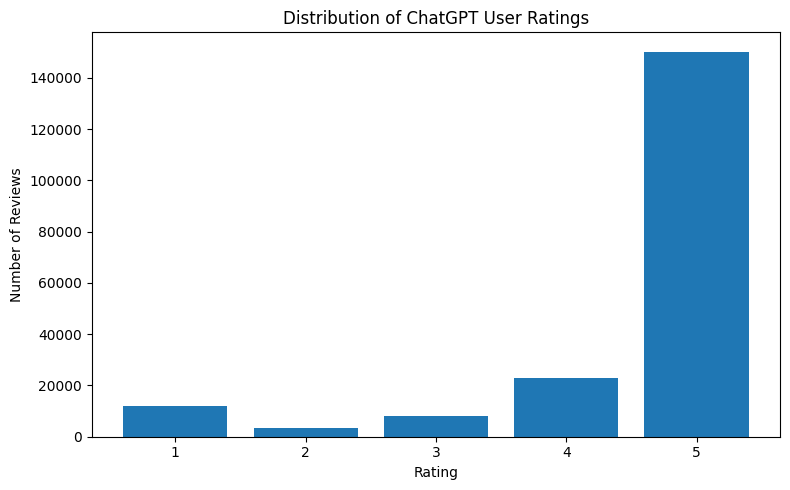

In [5]:

# Rating analysis

# Count reviews for each rating
rating_counts = df["ratings"].value_counts().sort_index()

print("Number of reviews for each rating:")
print(rating_counts)

print("\nAverage rating:", round(df["ratings"].mean(), 2))
print("Median rating:", df["ratings"].median())

# Create a bar chart
plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index.astype(str), rating_counts.values)

plt.title("Distribution of ChatGPT User Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


In [6]:

# Install and import TextBlob

!pip -q install textblob

from textblob import TextBlob

# Calculate sentiment polarity for each review
text_df["polarity"] = text_df["review"].apply(
    lambda review: TextBlob(review).sentiment.polarity
)

# Classify sentiment
def classify_sentiment(polarity):
    if polarity > 0.1:
        return "Positive"
    elif polarity < -0.1:
        return "Negative"
    else:
        return "Neutral"

text_df["sentiment"] = text_df["polarity"].apply(
    classify_sentiment
)

# Display sentiment results
print("Sentiment counts:")
print(text_df["sentiment"].value_counts())

print("\nSentiment percentages:")
print(
    (text_df["sentiment"].value_counts(normalize=True) * 100)
    .round(2)
)


Sentiment counts:
sentiment
Positive    145551
Neutral      44864
Negative      6306
Name: count, dtype: int64

Sentiment percentages:
sentiment
Positive    73.99
Neutral     22.81
Negative     3.21
Name: proportion, dtype: float64


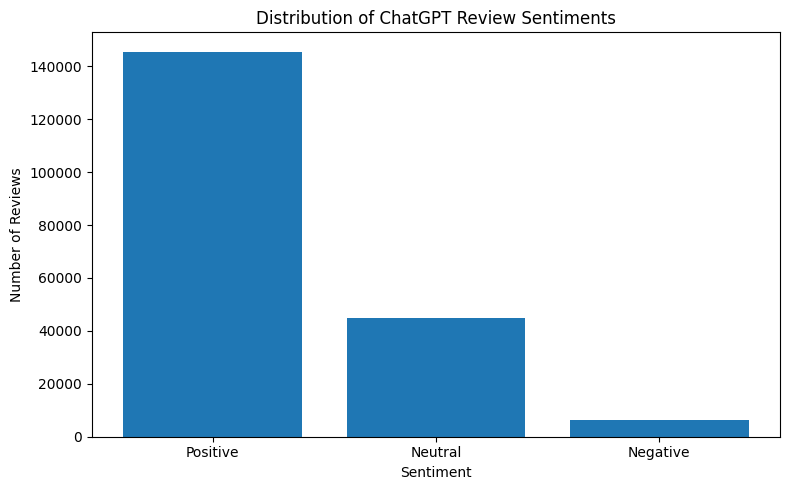

Average rating by sentiment:
sentiment
Negative    2.53
Neutral     4.16
Positive    4.69
Name: ratings, dtype: float64


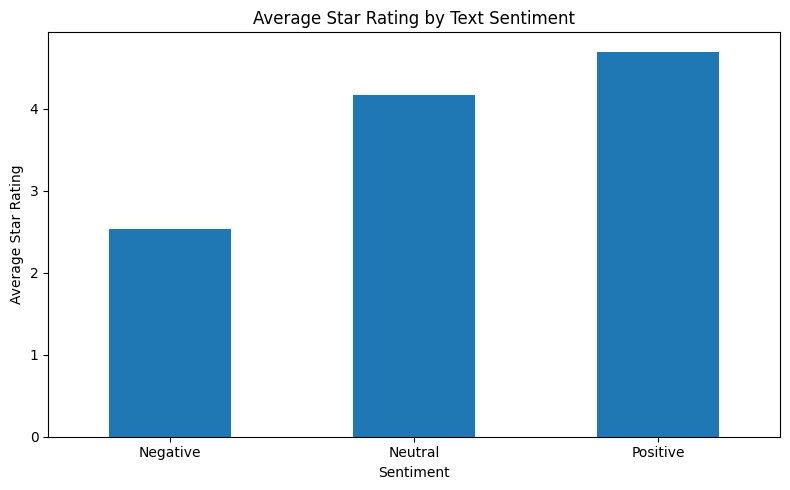

In [7]:

# Visualize sentiment analysis

# Chart 1: Sentiment distribution
sentiment_counts = text_df["sentiment"].value_counts().reindex(
    ["Positive", "Neutral", "Negative"], fill_value=0
)

plt.figure(figsize=(8, 5))
plt.bar(sentiment_counts.index, sentiment_counts.values)
plt.title("Distribution of ChatGPT Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

# Chart 2: Average rating by sentiment
sentiment_rating = text_df.groupby("sentiment")["ratings"].mean()

print("Average rating by sentiment:")
print(sentiment_rating.round(2))

sentiment_rating.plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Star Rating by Text Sentiment"
)
plt.xlabel("Sentiment")
plt.ylabel("Average Star Rating")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [8]:

# Keyword analysis

from sklearn.feature_extraction.text import CountVectorizer

# Separate positive and negative reviews
positive_reviews = text_df.loc[
    text_df["sentiment"] == "Positive", "review"
]

negative_reviews = text_df.loc[
    text_df["sentiment"] == "Negative", "review"
]

# Find the most frequent words in positive reviews
positive_vectorizer = CountVectorizer(
    stop_words="english", max_features=20
)

positive_matrix = positive_vectorizer.fit_transform(
    positive_reviews
)

positive_word_freq = pd.Series(
    positive_matrix.sum(axis=0).A1,
    index=positive_vectorizer.get_feature_names_out()
).sort_values(ascending=False)

# Find the most frequent words in negative reviews
negative_vectorizer = CountVectorizer(
    stop_words="english", max_features=20
)

negative_matrix = negative_vectorizer.fit_transform(
    negative_reviews
)

negative_word_freq = pd.Series(
    negative_matrix.sum(axis=0).A1,
    index=negative_vectorizer.get_feature_names_out()
).sort_values(ascending=False)

# Display the top 10 words from each group
print("Top 10 positive keywords:")
print(positive_word_freq.head(10))

print("\nTop 10 negative keywords:")
print(negative_word_freq.head(10))


Top 10 positive keywords:
app        43516
good       38778
best       18321
nice       13691
great      11798
ai          9828
helpful     9385
amazing     8568
love        8487
chatgpt     7811
dtype: int64

Top 10 negative keywords:
app        1768
bad         766
wrong       712
chatgpt     467
ai          434
use         410
just        399
like        396
answer      391
time        385
dtype: int64


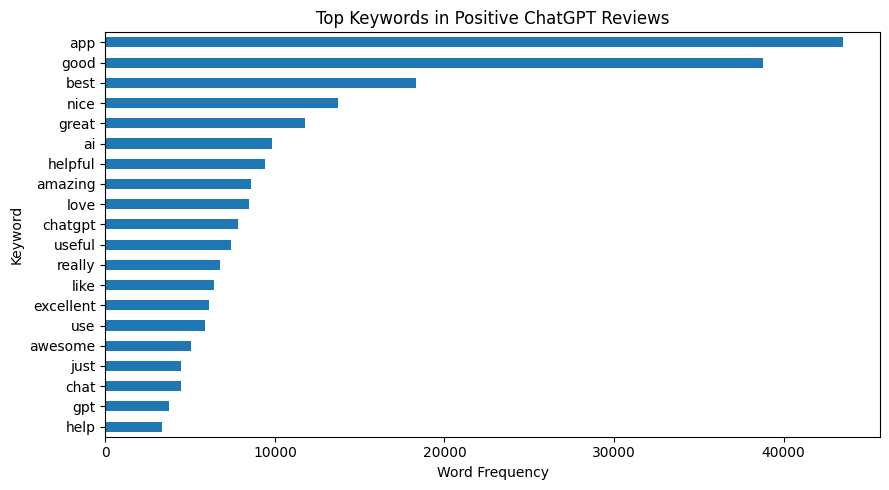

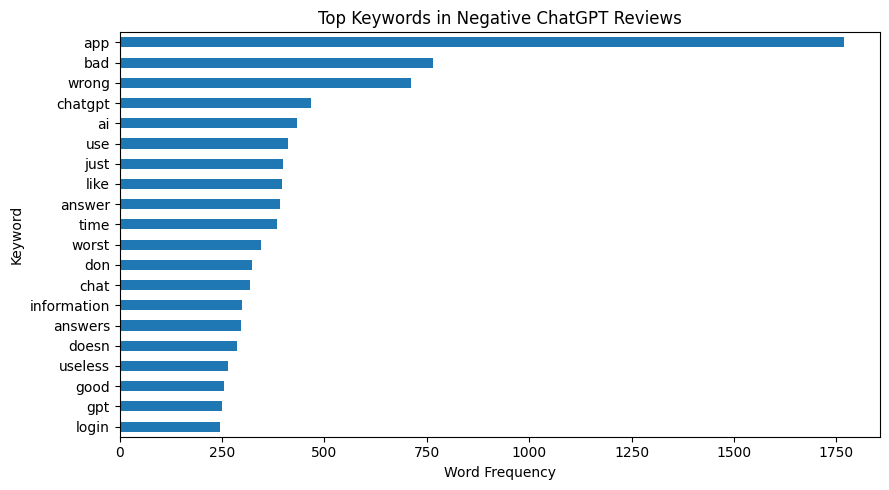

In [9]:

# Chart: Positive keywords
positive_word_freq.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Top Keywords in Positive ChatGPT Reviews"
)
plt.xlabel("Word Frequency")
plt.ylabel("Keyword")
plt.tight_layout()
plt.show()

# Chart: Negative keywords
negative_word_freq.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Top Keywords in Negative ChatGPT Reviews"
)
plt.xlabel("Word Frequency")
plt.ylabel("Keyword")
plt.tight_layout()
plt.show()


Monthly sentiment counts:


sentiment,Positive,Neutral,Negative
month,,,
2023-07,5752,2175,356
2023-08,4676,1816,309
2023-09,5537,1757,299
2023-10,4236,1399,189
2023-11,6405,2015,299
2023-12,7567,2451,357
2024-01,6667,2292,354
2024-02,6340,2060,348
2024-03,11143,3516,514


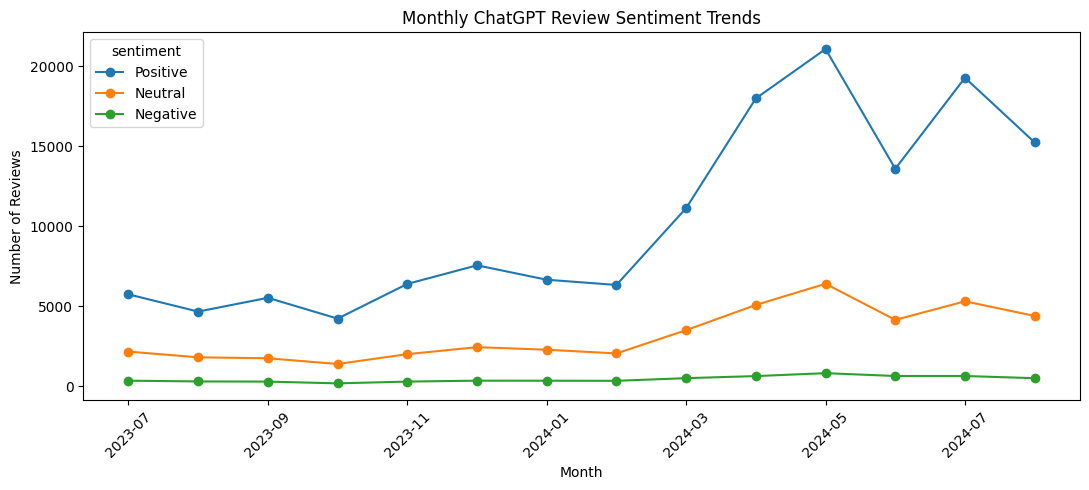

In [10]:

# Monthly sentiment trends

# Prepare the review dates
monthly = text_df.dropna(subset=["review date"]).copy()

monthly["month"] = (
    monthly["review date"].dt.to_period("M").astype(str)
)

# Count each sentiment for every month
monthly_counts = monthly.groupby(
    ["month", "sentiment"]
).size().unstack(fill_value=0)

# Keep sentiment categories in a consistent order
monthly_counts = monthly_counts.reindex(
    columns=["Positive", "Neutral", "Negative"],
    fill_value=0
)

print("Monthly sentiment counts:")
display(monthly_counts)

# Create a line chart
monthly_counts.plot(
    kind="line",
    figsize=(11, 5),
    marker="o"
)

plt.title("Monthly ChatGPT Review Sentiment Trends")
plt.xlabel("Month")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Monthly Average Ratings:


,ratings
month,
2023-07,4.44
2023-08,4.33
2023-09,4.49
2023-10,4.53
2023-11,4.52
2023-12,4.51
2024-01,4.47
2024-02,4.49
2024-03,4.49


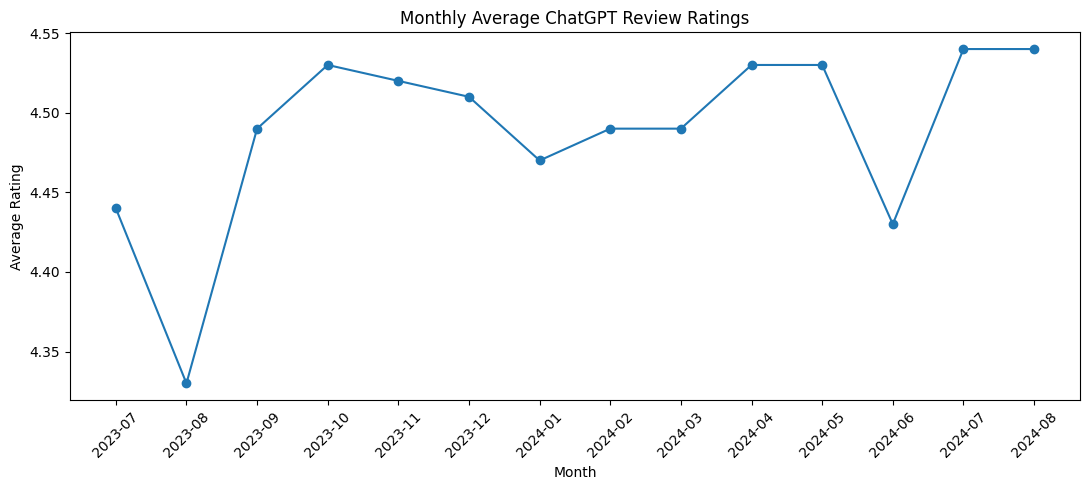

In [11]:

# Monthly average ratings

monthly_ratings = (
    monthly.groupby("month")["ratings"]
    .mean()
    .round(2)
)

print("Monthly Average Ratings:")
display(monthly_ratings)

# Visualize monthly average ratings
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_ratings.index,
    monthly_ratings.values,
    marker="o"
)

plt.title("Monthly Average ChatGPT Review Ratings")
plt.xlabel("Month")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [12]:

# Final project summary

print("CHATGPT REVIEWS ANALYSIS")
print("=" * 40)

print("\n1. Dataset")
print("Total records:", len(df))
print("Reviews with text:", len(text_df))

print("\n2. Ratings")
print("Average rating:", round(df["ratings"].mean(), 2))
print("Rating distribution:")
print(df["ratings"].value_counts().sort_index())

print("\n3. Sentiment percentages")
print(
    (text_df["sentiment"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\n4. Average rating by sentiment")
print(
    text_df.groupby("sentiment")["ratings"].mean().round(2)
)

print("\n5. Top positive keywords")
print(positive_word_freq.head(10))

print("\n6. Top negative keywords")
print(negative_word_freq.head(10))

print("\n7. Monthly analysis")
print("Months analyzed:", len(monthly_ratings))


CHATGPT REVIEWS ANALYSIS

1. Dataset
Total records: 196727
Reviews with text: 196721

2. Ratings
Average rating: 4.5
Rating distribution:
ratings
1     12083
2      3375
3      8157
4     22897
5    150215
Name: count, dtype: int64

3. Sentiment percentages
sentiment
Positive    73.99
Neutral     22.81
Negative     3.21
Name: proportion, dtype: float64

4. Average rating by sentiment
sentiment
Negative    2.53
Neutral     4.16
Positive    4.69
Name: ratings, dtype: float64

5. Top positive keywords
app        43516
good       38778
best       18321
nice       13691
great      11798
ai          9828
helpful     9385
amazing     8568
love        8487
chatgpt     7811
dtype: int64

6. Top negative keywords
app        1768
bad         766
wrong       712
chatgpt     467
ai          434
use         410
just        399
like        396
answer      391
time        385
dtype: int64

7. Monthly analysis
Months analyzed: 14
